# Movie Recommendation System 

This notebook implements the **main task**: user-based collaborative filtering, movie recommendations, and evaluation with Precision@10 and Recall@10. It also retains the latest exploratory experiment: similarity calculated using co-rated movies.

Dataset folder expected beside this notebook: `ml-latest-small/` containing `movies.csv` and `ratings.csv`.

## 1. Import libraries and load the datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

movies = pd.read_csv("ml-latest-small/movies.csv")
ratings = pd.read_csv("ml-latest-small/ratings.csv")

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)

display(movies.head())
display(ratings.head())

Movies shape: (9742, 3)
Ratings shape: (100836, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 2. Inspect and clean the data

In [2]:
print("Movies information:")
movies.info()

print("\\nMissing values in movies:")
print(movies.isna().sum())
print("Duplicate movie rows:", movies.duplicated().sum())

print("\\nRatings information:")
ratings.info()

print("\\nMissing values in ratings:")
print(ratings.isna().sum())
print("Duplicate rating rows:", ratings.duplicated().sum())

# Make genres safe for text processing
movies["genres"] = movies["genres"].fillna("")

Movies information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB
\nMissing values in movies:
movieId    0
title      0
genres     0
dtype: int64
Duplicate movie rows: 0
\nRatings information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
\nMissing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
Du

## 3. Basic dataset statistics

In [3]:
n_users = ratings["userId"].nunique()
n_rated_movies = ratings["movieId"].nunique()

print("Unique users:", n_users)
print("Movies rated:", n_rated_movies)
print("Average rating:", round(ratings["rating"].mean(), 2))
print("Rating range:", ratings["rating"].min(), "-", ratings["rating"].max())

movie_rating_counts = (
    ratings.groupby("movieId")
    .size()
    .sort_values(ascending=False)
    .rename("rating_count")
)

top_movies = (
    movies.merge(movie_rating_counts, on="movieId", how="inner")
    .sort_values("rating_count", ascending=False)
)

display(top_movies[["title", "genres", "rating_count"]].head(10))

Unique users: 610
Movies rated: 9724
Average rating: 3.5
Rating range: 0.5 - 5.0


,title,genres,rating_count
314,Forrest Gump (1994),Comedy|Drama|Romance|War,329
277,"Shawshank Redemption, The (1994)",Crime|Drama,317
257,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307
510,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279
1938,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278
224,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251
418,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,238
97,Braveheart (1995),Action|Drama|War,237
507,Terminator 2: Judgment Day (1991),Action|Sci-Fi,224
461,Schindler's List (1993),Drama|War,220


## 4. Visualize rating distribution

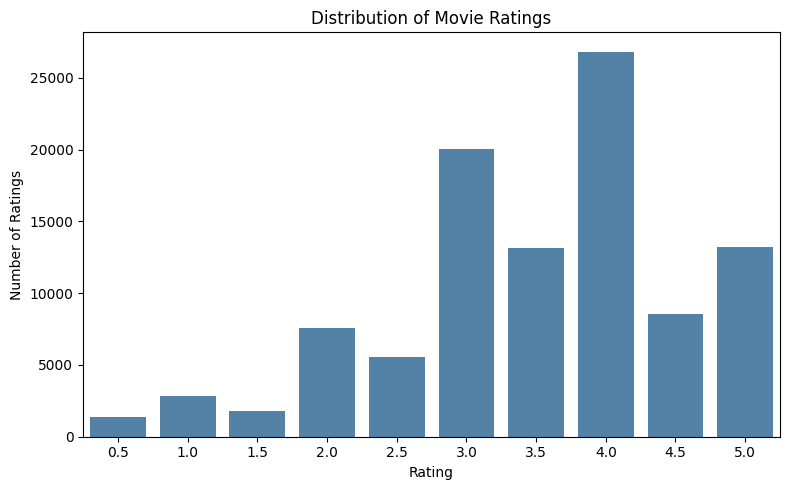

In [4]:
plt.figure(figsize=(8, 5))
sns.countplot(data=ratings, x="rating", color="steelblue")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

## 5. Content-based movie similarity (exploratory section)

In [5]:
tfidf = TfidfVectorizer(token_pattern=r"[^|]+")
tfidf_matrix = tfidf.fit_transform(movies["genres"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)

cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)
print("Movie similarity matrix shape:", cosine_sim.shape)

TF-IDF matrix shape: (9742, 20)
Movie similarity matrix shape: (9742, 9742)


In [6]:
def recommend_similar_movies(movie_title, top_n=5):
    matches = movies[
        movies["title"].str.contains(movie_title, case=False, regex=False, na=False)
    ]

    if matches.empty:
        print("Movie not found.")
        return pd.DataFrame(columns=["title", "genres"])

    movie_idx = matches.index[0]
    similarity_scores = list(enumerate(cosine_sim[movie_idx]))
    similarity_scores.sort(key=lambda x: x[1], reverse=True)

    top_indices = [
        idx for idx, score in similarity_scores if idx != movie_idx
    ][:top_n]

    return movies.iloc[top_indices][["title", "genres"]].reset_index(drop=True)

display(recommend_similar_movies("Toy Story", top_n=5))

,title,genres
0,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy
1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy
2,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy
3,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy
4,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy


## 6. Create the full User-Item Matrix (exploration)

In [7]:
user_item_matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Full User-Item Matrix shape:", user_item_matrix.shape)
display(user_item_matrix.iloc[:5, :10])

Full User-Item Matrix shape: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 7. Split ratings into training and testing sets

In [8]:
train_ratings, test_ratings = train_test_split(
    ratings,
    test_size=0.2,
    random_state=42
)

print("Training ratings:", train_ratings.shape)
print("Testing ratings:", test_ratings.shape)

Training ratings: (80668, 4)
Testing ratings: (20168, 4)


## 8. Create the training User-Item Matrix

In [9]:
train_user_item_matrix = train_ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Training User-Item Matrix shape:", train_user_item_matrix.shape)
display(train_user_item_matrix.iloc[:5, :10])

Training User-Item Matrix shape: (610, 8983)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 9. Calculate baseline user similarity

In [10]:
train_user_item_filled = train_user_item_matrix.fillna(0)

train_user_similarity = cosine_similarity(train_user_item_filled)

train_user_similarity_df = pd.DataFrame(
    train_user_similarity,
    index=train_user_item_matrix.index,
    columns=train_user_item_matrix.index
)

print("Training user similarity matrix shape:", train_user_similarity_df.shape)

similar_users_user1 = (
    train_user_similarity_df.loc[1]
    .drop(index=1)
    .sort_values(ascending=False)
)

display(similar_users_user1.head(5))

Training user similarity matrix shape: (610, 610)


userId
266    0.324689
368    0.297333
45     0.288969
480    0.288702
217    0.282339
Name: 1, dtype: float64

## 10. Build the User-Based recommender

In [13]:
def recommend_movies_from_train(
    user_id,
    n_recommendations=10,
    n_neighbors=50,
    min_support=3
):
    columns = [
        "movieId", "title", "genres",
        "Predicted Rating", "Similar Users Count"
    ]

    if user_id not in train_user_item_matrix.index:
        return pd.DataFrame(columns=columns)

    similar_users = (
        train_user_similarity_df.loc[user_id]
        .drop(index=user_id)
        .sort_values(ascending=False)
        .head(n_neighbors)
    )

    neighbor_ratings = train_user_item_matrix.loc[similar_users.index]

    # Weighted sum of ratings; missing ratings do not contribute to numerator
    weighted_ratings = neighbor_ratings.fillna(0).mul(
        similar_users, axis=0
    ).sum(axis=0)

    # Sum only the similarities for neighbors who actually rated each movie
    rating_weights = neighbor_ratings.notna().mul(
        similar_users, axis=0
    ).sum(axis=0)

    predicted_ratings = weighted_ratings.div(
        rating_weights.replace(0, np.nan)
    )

    rating_counts = neighbor_ratings.notna().sum(axis=0)

    # Do not recommend movies already rated by this user in training
    already_rated = train_user_item_matrix.loc[user_id].dropna().index
    predicted_ratings = predicted_ratings.drop(
        index=already_rated, errors="ignore"
    )

    candidates = pd.DataFrame({
        "movieId": predicted_ratings.index,
        "Predicted Rating": predicted_ratings.values,
        "Similar Users Count": rating_counts.reindex(
            predicted_ratings.index
        ).values
    })

    candidates = candidates[
        (candidates["Similar Users Count"] >= min_support)
        & candidates["Predicted Rating"].notna()
    ]

    candidates = candidates.sort_values(
        ["Predicted Rating", "Similar Users Count"],
        ascending=[False, False]
    ).head(n_recommendations)

    recommendations = candidates.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    return recommendations[columns].reset_index(drop=True)

## 11. Test recommendations for a user

In [14]:
display(recommend_movies_from_train(user_id=1, n_recommendations=10))

,movieId,title,genres,Predicted Rating,Similar Users Count
0,1248,Touch of Evil (1958),Crime|Film-Noir|Thriller,5.000000,3
1,1411,Hamlet (1996),Crime|Drama|Romance,5.000000,3
2,475,In the Name of the Father (1993),Drama,4.845218,3
3,3060,"Commitments, The (1991)",Comedy|Drama|Musical,4.778793,4
4,79702,Scott Pilgrim vs. the World (2010),Action|Comedy|Fantasy|Musical|Romance,4.769706,4
5,1104,"Streetcar Named Desire, A (1951)",Drama,4.714765,5
6,8132,Gladiator (1992),Action|Drama,4.685707,3
7,3153,"7th Voyage of Sinbad, The (1958)",Action|Adventure|Fantasy,4.673700,3
8,5292,Slap Shot (1977),Comedy,4.667812,3
9,3328,Ghost Dog: The Way of the Samurai (1999),Crime|Drama,4.667324,3


## 12. Evaluate Precision@10 across users

In [21]:
k = 10
precision_scores = []

# Restrict relevance to movies present in training, since the current
# collaborative-filtering model cannot recommend unseen movie IDs.
train_movie_ids = set(train_ratings["movieId"].unique())

for user_id in test_ratings["userId"].unique():
    relevant_movies = set(
        test_ratings[
            (test_ratings["userId"] == user_id)
            & (test_ratings["rating"] >= 4.0)
            & (test_ratings["movieId"].isin(train_movie_ids))
        ]["movieId"]
    )

    if not relevant_movies:
        continue

    recommendations = recommend_movies_from_train(
        user_id=user_id,
        n_recommendations=k
    )
    recommended_movie_ids = set(recommendations["movieId"].tolist())

    hits = len(recommended_movie_ids & relevant_movies)
    precision_scores.append(hits / k)

mean_precision = float(np.mean(precision_scores)) if precision_scores else 0.0

print("Users evaluated:", len(precision_scores))
print(f"Mean Precision@{k}: {mean_precision:.4f}")
print(f"Mean Precision@{k} (%): {mean_precision * 100:.2f}%")

Users evaluated: 598
Mean Precision@10: 0.0231
Mean Precision@10 (%): 2.31%


## 13. Evaluate Recall@10 across users

In [20]:
recall_scores = []

for user_id in test_ratings["userId"].unique():
    relevant_movies = set(
        test_ratings[
            (test_ratings["userId"] == user_id)
            & (test_ratings["rating"] >= 4.0)
            & (test_ratings["movieId"].isin(train_movie_ids))
        ]["movieId"]
    )

    if not relevant_movies:
        continue

    recommendations = recommend_movies_from_train(
        user_id=user_id,
        n_recommendations=k
    )
    recommended_movie_ids = set(recommendations["movieId"].tolist())

    hits = len(recommended_movie_ids & relevant_movies)
    recall_scores.append(hits / len(relevant_movies))

mean_recall = float(np.mean(recall_scores)) if recall_scores else 0.0

print("Users evaluated:", len(recall_scores))
print(f"Mean Recall@{k}: {mean_recall:.4f}")
print(f"Mean Recall@{k} (%): {mean_recall * 100:.2f}%")

Users evaluated: 598
Mean Recall@10: 0.0311
Mean Recall@10 (%): 3.11%


## 14. Check train/test coverage

In [17]:
train_users = set(train_ratings["userId"].unique())
test_users = set(test_ratings["userId"].unique())
train_movies = set(train_ratings["movieId"].unique())
test_movies = set(test_ratings["movieId"].unique())

print("Users in training:", len(train_users))
print("Users in testing:", len(test_users))
print("Test users missing from training:", len(test_users - train_users))
print("Movies in training:", len(train_movies))
print("Movies in testing:", len(test_movies))
print("Test movies missing from training:", len(test_movies - train_movies))

unseen_test_ratings = test_ratings[
    ~test_ratings["movieId"].isin(train_movies)
]
unseen_relevant = unseen_test_ratings[
    unseen_test_ratings["rating"] >= 4.0
]

print("\\nTotal test ratings:", len(test_ratings))
print("Test ratings for unseen movies:", len(unseen_test_ratings))
print(
    "Percentage of test ratings for unseen movies:",
    f"{len(unseen_test_ratings) / len(test_ratings) * 100:.2f}%"
)
print("Relevant ratings for unseen movies:", len(unseen_relevant))

Users in training: 610
Users in testing: 610
Test users missing from training: 0
Movies in training: 8983
Movies in testing: 5142
Test movies missing from training: 741
\nTotal test ratings: 20168
Test ratings for unseen movies: 813
Percentage of test ratings for unseen movies: 4.03%
Relevant ratings for unseen movies: 310


## 15. Inspect co-rated movies for the top similar users

In [18]:
user_id = 1

similar_users = (
    train_user_similarity_df.loc[user_id]
    .drop(index=user_id)
    .sort_values(ascending=False)
    .head(5)
)

for other_user_id in similar_users.index:
    common_movies = (
        train_user_item_matrix.loc[user_id].notna()
        & train_user_item_matrix.loc[other_user_id].notna()
    ).sum()

    print(f"User {other_user_id}: {common_movies} movies rated by both users")

User 266: 49 movies rated by both users
User 368: 74 movies rated by both users
User 45: 72 movies rated by both users
User 480: 93 movies rated by both users
User 217: 86 movies rated by both users


## 16. Latest experiment: similarity using co-rated movies only

In [19]:
# This is an experiment only. The recommender above still uses the baseline
# train_user_similarity_df until we explicitly compare and choose a model.

n_users = len(train_user_item_matrix)
user_ids = train_user_item_matrix.index.tolist()
co_rated_similarity = np.zeros((n_users, n_users), dtype=float)

for i in range(n_users):
    user_i = train_user_item_matrix.iloc[i]

    for j in range(i, n_users):
        user_j = train_user_item_matrix.iloc[j]
        common = user_i.notna() & user_j.notna()

        if common.sum() >= 3:
            ratings_i = user_i[common].to_numpy().reshape(1, -1)
            ratings_j = user_j[common].to_numpy().reshape(1, -1)
            score = cosine_similarity(ratings_i, ratings_j)[0, 0]
        else:
            score = 0.0

        co_rated_similarity[i, j] = score
        co_rated_similarity[j, i] = score

co_rated_similarity_df = pd.DataFrame(
    co_rated_similarity,
    index=user_ids,
    columns=user_ids
)

print("Co-rated similarity matrix shape:", co_rated_similarity_df.shape)
print("\\nTop 5 similar users to User 1 using co-rated movies:")
display(
    co_rated_similarity_df.loc[1]
    .drop(index=1)
    .sort_values(ascending=False)
    .head(5)
)

Co-rated similarity matrix shape: (610, 610)
\nTop 5 similar users to User 1 using co-rated movies:


77     1.000000
511    1.000000
194    0.999025
398    0.998918
366    0.998875
Name: 1, dtype: float64

## Notes

- The baseline recommender uses only training ratings for similarity and recommendations.
- `Predicted Rating` is an estimate, not the movie's actual average rating.
- Precision@10 and Recall@10 are evaluated against positive test ratings (`rating >= 4.0`) for movies that appeared in training, so the model is evaluated only on items it could potentially recommend.
- The co-rated similarity matrix at the end is an experiment. It has **not** been plugged into the recommender or shown to be better yet.
- Run the notebook from top to bottom using **Kernel → Restart Kernel and Run All Cells** after confirming the dataset folder is next to the notebook.